# Predicting Income Level with Logistic Regression


In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve)



In [2]:
df = pd.read_csv("adult.csv")
print("Shape:", df.shape)
df.head()

Shape: (32561, 15)


,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             32561 non-null  int64
 1   workclass       32561 non-null  str  
 2   fnlwgt          32561 non-null  int64
 3   education       32561 non-null  str  
 4   education.num   32561 non-null  int64
 5   marital.status  32561 non-null  str  
 6   occupation      32561 non-null  str  
 7   relationship    32561 non-null  str  
 8   race            32561 non-null  str  
 9   sex             32561 non-null  str  
 10  capital.gain    32561 non-null  int64
 11  capital.loss    32561 non-null  int64
 12  hours.per.week  32561 non-null  int64
 13  native.country  32561 non-null  str  
 14  income          32561 non-null  str  
dtypes: int64(6), str(9)
memory usage: 3.7 MB


income
<=50K    24720
>50K      7841
Name: count, dtype: int64
income
<=50K    0.759
>50K     0.241
Name: proportion, dtype: float64


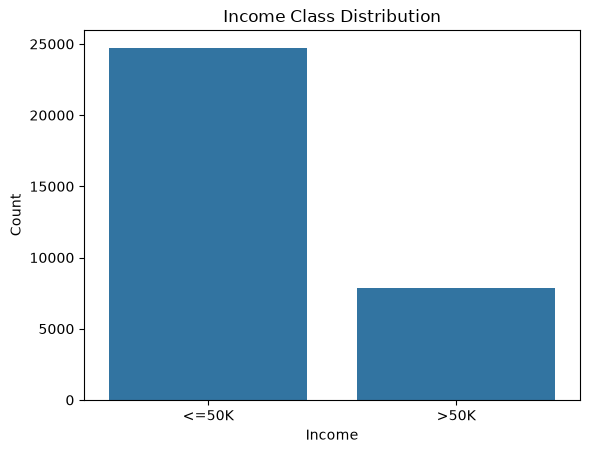

In [4]:

print(df["income"].value_counts())


print(df["income"].value_counts(normalize=True).round(3))

sns.countplot(data=df, x="income", order=["<=50K", ">50K"])

plt.title("Income Class Distribution")
plt.xlabel("Income")
plt.ylabel("Count")
plt.show()

In [8]:
#Missing values
print("Real NaNs:", df.isna().sum().sum())
print()
missing_q = (df == "?").sum()
print(missing_q[missing_q > 0])
print()
print((missing_q[missing_q > 0] / len(df) * 100).round(1).astype(str) + " %")

Real NaNs: 0

Series([], dtype: int64)

Series([], dtype: str)


In [9]:
df = df.replace("?", np.nan)
for col in ["workclass", "occupation", "native.country"]:
    df[col] = df[col].fillna("Unknown")

print("Remaining missing values:", df.isna().sum().sum())

Remaining missing values: 0


In [10]:
#  how many people have zero capital gain and loss
print("Zero capital gain:", (df["capital.gain"] == 0).mean().round(3))
print("Zero capital loss:", (df["capital.loss"] == 0).mean().round(3))

Zero capital gain: 0.917
Zero capital loss: 0.953


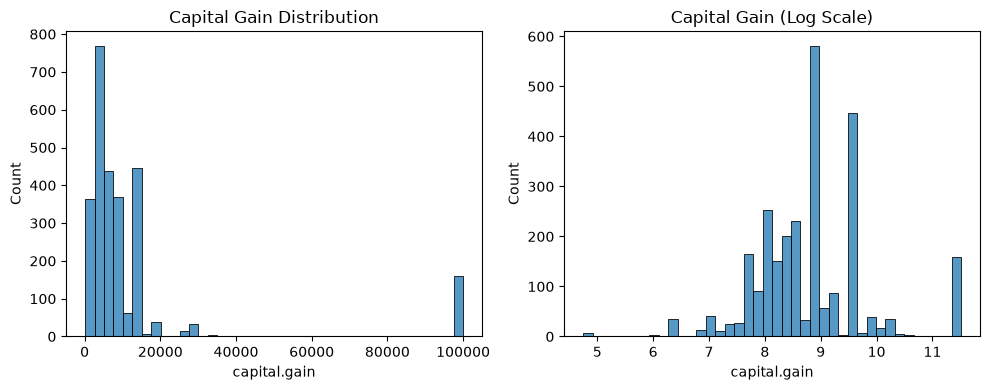

In [11]:
# Distribution of capital gain
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
sns.histplot(df[df["capital.gain"] > 0]["capital.gain"], bins=40)
plt.title("Capital Gain Distribution")


plt.subplot(1, 2, 2)
sns.histplot(np.log1p(df[df["capital.gain"] > 0]["capital.gain"]), bins=40)
plt.title("Capital Gain (Log Scale)")

plt.tight_layout()
plt.show()

In [12]:
df["capital.gain"] = np.log1p(df["capital.gain"])
df["capital.loss"] = np.log1p(df["capital.loss"])

df["target"] = (df["income"] == ">50K").astype(int)
df[["capital.gain", "capital.loss", "target"]].describe().round(2)

,capital.gain,capital.loss,target
count,32561.00,32561.00,32561.00
mean,0.73,0.35,0.24
std,2.45,1.58,0.43
min,0.00,0.00,0.00
25%,0.00,0.00,0.00
50%,0.00,0.00,0.00
75%,0.00,0.00,0.00
max,11.51,8.38,1.00


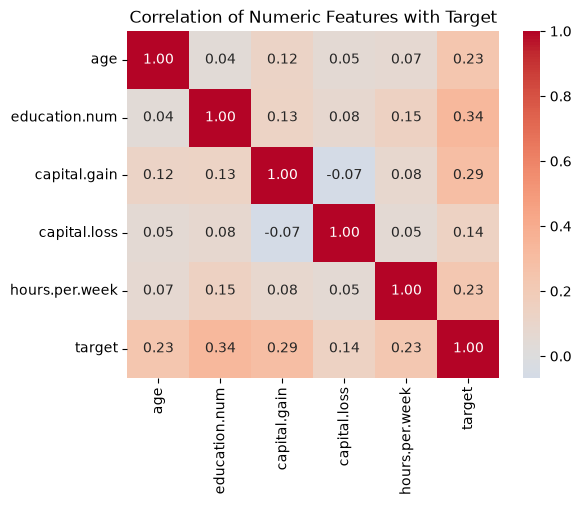

In [13]:
#Feature Selection

num_cols = ["age", "education.num", "capital.gain",
            "capital.loss", "hours.per.week", "target"]


plt.figure(figsize=(6, 4.5))

sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", center=0)

plt.title("Correlation of Numeric Features with Target")
plt.show()

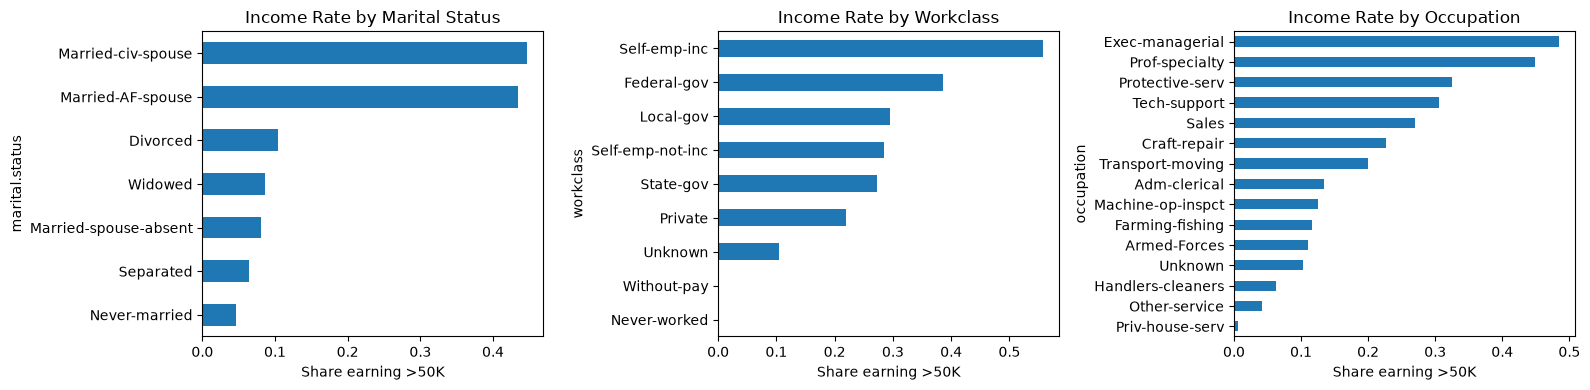

In [14]:
# Income rate by marital status, workclass and occupation
plt.figure(figsize=(16, 4))

plt.subplot(1, 3, 1)
df.groupby("marital.status")["target"].mean().sort_values().plot.barh()
plt.title("Income Rate by Marital Status")
plt.xlabel("Share earning >50K")

plt.subplot(1, 3, 2)
df.groupby("workclass")["target"].mean().sort_values().plot.barh()
plt.title("Income Rate by Workclass")
plt.xlabel("Share earning >50K")

plt.subplot(1, 3, 3)
df.groupby("occupation")["target"].mean().sort_values().plot.barh()
plt.title("Income Rate by Occupation")
plt.xlabel("Share earning >50K")

plt.tight_layout()
plt.show()

In [15]:
check = df.groupby("education")["education.num"].nunique()

print("Maximum distinct values:", check.max())


education_data = df[["education", "education.num"]].drop_duplicates()

education_data = education_data.sort_values("education.num").reset_index(drop=True)

print(education_data)

Maximum distinct values: 1
       education  education.num
0      Preschool              1
1        1st-4th              2
2        5th-6th              3
3        7th-8th              4
4            9th              5
5           10th              6
6           11th              7
7           12th              8
8        HS-grad              9
9   Some-college             10
10     Assoc-voc             11
11    Assoc-acdm             12
12     Bachelors             13
13       Masters             14
14   Prof-school             15
15     Doctorate             16


In [16]:
df["from_us"] = (df["native.country"] == "United-States").astype(int)

DROP = ["income", "target", "native.country", "education", "fnlwgt", "relationship", "sex", "race"]
X = df.drop(columns=DROP)
y = df["target"]

num_features = X.select_dtypes(include="number").columns.tolist()
cat_features = X.select_dtypes(exclude="number").columns.tolist()

print("Numeric features:    ", num_features)
print("Categorical features:", cat_features)

Numeric features:     ['age', 'education.num', 'capital.gain', 'capital.loss', 'hours.per.week', 'from_us']
Categorical features: ['workclass', 'marital.status', 'occupation']


In [18]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


print("Training income share:", round(y_train.mean(), 3))
print("Testing income share:", round(y_test.mean(), 3))

Training data: (26048, 9)
Testing data: (6513, 9)
Training income share: 0.241
Testing income share: 0.241


In [22]:
# Scale numerical features
scaler = StandardScaler()

X_train_num = scaler.fit_transform(X_train[num_features])
X_test_num = scaler.transform(X_test[num_features])


encoder = OneHotEncoder(handle_unknown="ignore")

X_train_cat = encoder.fit_transform(X_train[cat_features]).toarray()
X_test_cat = encoder.transform(X_test[cat_features]).toarray()


X_train_final = np.hstack((X_train_num, X_train_cat))
X_test_final = np.hstack((X_test_num, X_test_cat))


model = LogisticRegression(max_iter=2000, random_state=42)
model.fit(X_train_final, y_train)



,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",2000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

### Confusion matrix

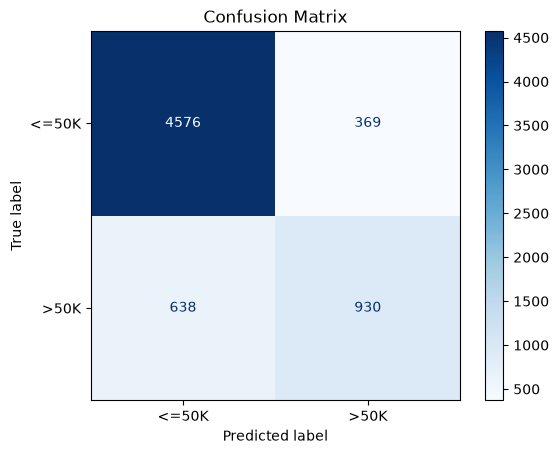

True Negatives: 4576
False Positives: 369
False Negatives: 638
True Positives: 930


In [23]:
# Make predictions
y_pred = model.predict(X_test_final)
y_prob = model.predict_proba(X_test_final)[:, 1]

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred)


disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["<=50K", ">50K"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix")
plt.show()


tn, fp, fn, tp = cm.ravel()


print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

In [24]:
# Calculate model performance
print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred), 3))
print("Recall:", round(recall_score(y_test, y_pred), 3))
print("F1-score:", round(f1_score(y_test, y_pred), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 3))

baseline = 1 - y_test.mean()
print("\nBaseline Accuracy:", round(baseline, 3))


print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=["<=50K", ">50K"],
    digits=3
))

Accuracy: 0.845
Precision: 0.716
Recall: 0.593
F1-score: 0.649
ROC-AUC: 0.896

Baseline Accuracy: 0.759

Classification Report:
              precision    recall  f1-score   support

       <=50K      0.878     0.925     0.901      4945
        >50K      0.716     0.593     0.649      1568

    accuracy                          0.845      6513
   macro avg      0.797     0.759     0.775      6513
weighted avg      0.839     0.845     0.840      6513



###  ROC curve

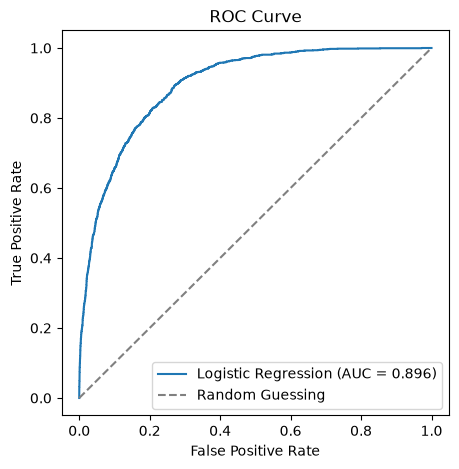

In [25]:

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

auc = roc_auc_score(y_test, y_prob)


plt.figure(figsize=(5, 5))

plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "--", color="grey", label="Random Guessing")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

In [28]:
# Split training data into 5 parts
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

auc_scores = []
f1_scores = []

for train_index, val_index in cv.split(X_train, y_train):

   
    X1, X2 = X_train.iloc[train_index], X_train.iloc[val_index]
    y1, y2 = y_train.iloc[train_index], y_train.iloc[val_index]

    
    scaler = StandardScaler()
    X1_num = scaler.fit_transform(X1[num_features])
    X2_num = scaler.transform(X2[num_features])

    
    encoder = OneHotEncoder(handle_unknown="ignore")
    X1_cat = encoder.fit_transform(X1[cat_features]).toarray()
    X2_cat = encoder.transform(X2[cat_features]).toarray()

    
    X1_final = np.hstack((X1_num, X1_cat))
    X2_final = np.hstack((X2_num, X2_cat))

    
    model = LogisticRegression(max_iter=2000)
    model.fit(X1_final, y1)

    predictions = model.predict(X2_final)
    probabilities = model.predict_proba(X2_final)[:, 1]

    auc_scores.append(roc_auc_score(y2, probabilities))
    f1_scores.append(f1_score(y2, predictions))


print("Average ROC-AUC:", round(np.mean(auc_scores), 3))
print("Average F1-score:", round(np.mean(f1_scores), 3))

Average ROC-AUC: 0.897
Average F1-score: 0.641


In [29]:
for t in [0.3, 0.4, 0.5, 0.6]:
    prediction = (y_prob >= t).astype(int)

    print("Threshold:", t)
    print("Precision:", round(precision_score(y_test, prediction), 3))
    print("Recall:", round(recall_score(y_test, prediction), 3))
    print("F1-score:", round(f1_score(y_test, prediction), 3))
    print()

Threshold: 0.3
Precision: 0.605
Recall: 0.77
F1-score: 0.678

Threshold: 0.4
Precision: 0.663
Recall: 0.678
F1-score: 0.67

Threshold: 0.5
Precision: 0.716
Recall: 0.593
F1-score: 0.649

Threshold: 0.6
Precision: 0.774
Recall: 0.496
F1-score: 0.604



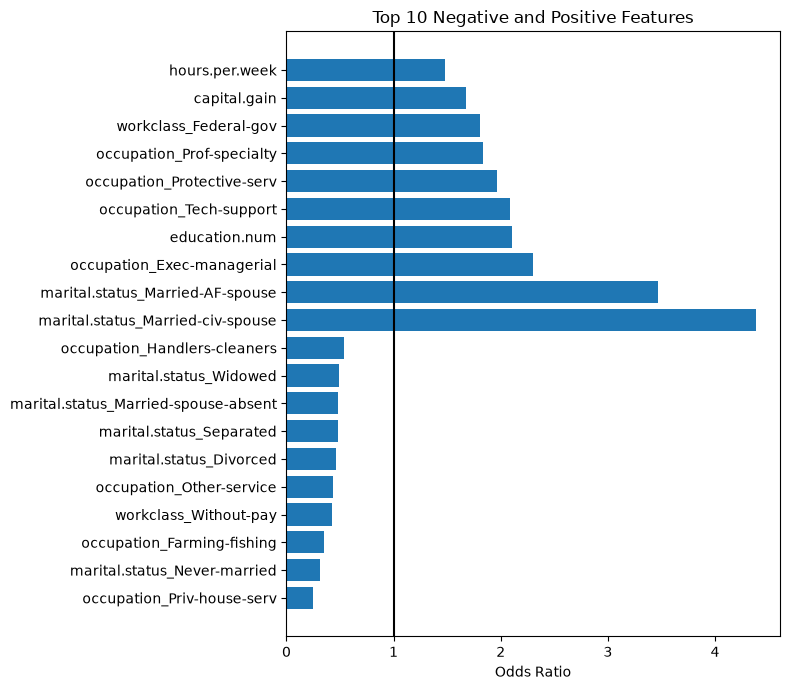

In [30]:
#FEATURES
feature_names = list(num_features) + list(encoder.get_feature_names_out(cat_features))


odds = pd.Series(np.exp(model.coef_[0]), index=feature_names)


top = pd.concat([odds.nsmallest(10), odds.nlargest(10)])


plt.figure(figsize=(8, 7))
plt.barh(top.index, top.values)
plt.axvline(1, color="black")
plt.title("Top 10 Negative and Positive Features")
plt.xlabel("Odds Ratio")
plt.tight_layout()
plt.show()